# UdaPlay - Part 2: The Research Agent

This notebook builds the UdaPlay agent on top of the knowledge base from Part 1 and runs it on example questions.

**Tools**
1. `retrieve_game` - semantic search over the local dataset (and over long-term memory)
2. `evaluate_retrieval` - an LLM judge that decides whether the retrieved documents can answer the question
3. `game_web_search` - Tavily web search, used only when the evaluation says internal knowledge is insufficient

**Workflow (state machine)**
```
__entry__ -> message_prep -> llm_processor --tool calls--> tool_executor --+
                                  ^                                       |
                                  +---------------------------------------+
                                  | no more tool calls
                                  v
                             format_answer -> persist_memory -> __termination__
```
- The first two LLM calls of every turn are forced (`tool_choice`) to `retrieve_game` and then `evaluate_retrieval`,
  so no answer skips internal knowledge or its evaluation. The model then decides whether to search the web.
- `tool_executor` enforces the order *retrieve -> evaluate -> web search*: a web search attempted before the
  internal knowledge was checked and evaluated is rejected and returned to the model as an error.
- `format_answer` produces a **structured answer** (natural language + JSON, with citations and confidence).
- `persist_memory` saves facts learned from the web to **long-term memory** (a separate Chroma collection),
  so future sessions can answer them without searching again.
- **Short-term memory** keeps each session's conversation, so follow-up questions work.

In [1]:
# Only needed in the Udacity workspace (old system sqlite). On your own machine this does nothing.
try:
    __import__("pysqlite3")
    import sys
    sys.modules["sqlite3"] = sys.modules.pop("pysqlite3")
except ImportError:
    pass

## Setup

In [2]:
import os
from dotenv import load_dotenv, find_dotenv

# find_dotenv() finds the .env file in this folder (or a parent folder);
# override=True makes the values in .env win over anything already set.
load_dotenv(find_dotenv(usecwd=True), override=True)

assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY is not set"
assert os.getenv("OPENAI_BASE_URL"), "OPENAI_BASE_URL is not set"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY is not set"
print("Environment OK")

Environment OK


In [3]:
%matplotlib inline
import json

import chromadb
from tavily import TavilyClient

from lib.agent import UdaPlayAgent
from lib.llm import LLM
from lib.memory import LongTermMemory
from lib.report import plot_retrieval, print_result, route_of
from lib.tools import create_udaplay_tools
from lib.vector_db import get_embedding_function, get_games_collection

chroma_client = chromadb.PersistentClient(path="chromadb")
embedding_fn = get_embedding_function()   # same OpenAI embedding function as Part 1
games_collection = get_games_collection(chroma_client, embedding_fn)
long_term_memory = LongTermMemory(chroma_client, embedding_fn)

print(f"Games collection: {games_collection.count()} documents")
print(f"Long-term memory: {long_term_memory.count()} learned facts")

Games collection: 20 documents
Long-term memory: 1 learned facts


Long-term memory persists across runs. To make this demo reproducible, it is cleared here so the first
web-search question really goes to the web. Set `RESET_LONG_TERM_MEMORY = False` to keep what was learned.

In [4]:
RESET_LONG_TERM_MEMORY = True
if RESET_LONG_TERM_MEMORY:
    long_term_memory.clear()
print(f"Long-term memory: {long_term_memory.count()} learned facts")

Long-term memory: 0 learned facts


## 1. Tools
The tools are plain Python functions (see `lib/tools.py`) wrapped with a `@tool` decorator (`lib/tooling.py`)
that derives the OpenAI function schema from the type hints and docstring.

In [5]:
judge_llm = LLM(temperature=0)           # LLM-as-judge used inside evaluate_retrieval
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

tools = create_udaplay_tools(games_collection, judge_llm, tavily_client, long_term_memory=long_term_memory)
retrieve_game, evaluate_retrieval, game_web_search = tools

for t in tools:
    print(json.dumps(t.to_api(), indent=2))

{
  "type": "function",
  "function": {
    "name": "retrieve_game",
    "description": "Semantic search over UdaPlay's internal knowledge: the local video game dataset plus facts previously learned from web searches (long-term memory). Always call this first.",
    "parameters": {
      "properties": {
        "query": {
          "description": "A self-contained search query about a video game, e.g. \"Who published Grand Theft Auto: San Andreas\". Resolve pronouns using the conversation.",
          "type": "string"
        }
      },
      "required": [
        "query"
      ],
      "type": "object"
    }
  }
}
{
  "type": "function",
  "function": {
    "name": "evaluate_retrieval",
    "description": "Judge whether the documents from retrieve_game are good enough to answer the question. Returns useful, confidence, a description, and should_search_web. Call this right after retrieve_game.",
    "parameters": {
      "properties": {
        "question": {
          "description": "T

### Tool 1 - `retrieve_game`

In [6]:
docs = retrieve_game(query="Who published Grand Theft Auto: San Andreas?")
for d in docs:
    print(f"{d['similarity']:.3f}  {d['source']:<14} {d['title']}")

0.689  local_dataset  Grand Theft Auto: San Andreas
0.596  local_dataset  Grand Theft Auto V
0.383  local_dataset  Minecraft


### Tool 2 - `evaluate_retrieval`
A question the dataset can answer, and one it can't:

In [7]:
print(json.dumps(evaluate_retrieval(question="Who published Grand Theft Auto: San Andreas?", retrieved_docs=docs), indent=2))

news_docs = retrieve_game(query="What is Rockstar Games working on right now?")
print(json.dumps(evaluate_retrieval(question="What is Rockstar Games working on right now?", retrieved_docs=news_docs), indent=2))

{
  "useful": true,
  "confidence": "high",
  "description": "The document clearly states that Rockstar Games is the publisher of Grand Theft Auto: San Andreas.",
  "missing_information": "",
  "best_similarity": 0.6885,
  "should_search_web": false
}


{
  "useful": false,
  "confidence": "high",
  "description": "The documents only provide information about past games developed by Rockstar Games, not their current projects.",
  "missing_information": "Current projects or games Rockstar Games is working on right now.",
  "best_similarity": 0.526,
  "should_search_web": true
}


### Tool 3 - `game_web_search`

In [8]:
web = game_web_search(question="Rockstar Games latest game in development")
print("Tavily answer:", web["answer"])
for r in web["results"]:
    print("-", r["title"], "|", r["url"])

Tavily answer: Rockstar Games' latest game in development is GTA 6, set to release on November 19, 2026. Additionally, Rockstar is collaborating with Remedy Entertainment to remake Max Payne 1 and 2, which is currently in full production. While specific details about other potential projects remain undisclosed, reports suggest that Rockstar is exploring or building additional offerings behind the scenes.
- Every Upcoming Rockstar Games Title in Development ... | https://www.imdb.com/news/ni65706242
- Rockstar Games Is Working On A New Game... (It's Not GTA 6) | https://www.youtube.com/watch?v=HeJZF23l4Ic
- Rockstar Games - Wikipedia | https://en.wikipedia.org/wiki/Rockstar_Games
- Beyond GTA 6: Other Rockstar Projects in the Works | https://www.1v1me.com/blog/beyond-gta6-other-rockstar-projects
- Rockstar Games' Future - Rockstar Games - GTAForums | https://gtaforums.com/topic/1000314-rockstar-games-future


## 2. The agent

In [9]:
agent = UdaPlayAgent(llm=LLM(temperature=0), tools=tools, long_term_memory=long_term_memory)

print("Steps:", list(agent.workflow.steps))
for t in agent.workflow.transitions.values():
    print(f"  {t.source:<15} -> {t.targets}{'  (conditional)' if t.condition else ''}")

Steps: ['__entry__', 'message_prep', 'llm_processor', 'tool_executor', 'format_answer', 'persist_memory', '__termination__']
  __entry__       -> ['message_prep']
  message_prep    -> ['llm_processor']
  llm_processor   -> ['tool_executor', 'format_answer']  (conditional)
  tool_executor   -> ['llm_processor']
  format_answer   -> ['persist_memory']
  persist_memory  -> ['__termination__']


## 3. Example queries
All queries below run in **one session** (`session_id="demo"`), so the agent can resolve follow-ups like
*"their"* and *"that one"*. Each result shows the workflow path, every tool call with a summary of its
result, the agent's reasoning, the final cited answer, and the structured JSON.

In [10]:
results = []

def ask(question: str, session_id: str = "demo", show_json: bool = False):
    result = agent.invoke(question, session_id=session_id)
    results.append(result)
    print_result(result, show_json=show_json)
    return result

### Query 1 - publisher (local dataset)

In [11]:
ask("Who published Grand Theft Auto: San Andreas?", show_json=True);

QUESTION: Who published Grand Theft Auto: San Andreas?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='Who published Grand Theft Auto: San Andreas?')
       -> Grand Theft Auto: San Andreas (local_dataset, sim=0.69); Grand Theft Auto V
       (local_dataset, sim=0.60); Minecraft (local_dataset, sim=0.38)
  2. evaluate_retrieval(question='Who published Grand Theft Auto: San Andreas?')
       -> useful=True, confidence=high, should_search_web=False - The document clearly states that
       Rockstar Games is the publisher of Grand Theft Auto: San Andreas.

REASONING:
    The information was directly retrieved from the local dataset, which clearly states that
    Rockstar Games is the publisher of Grand Theft Auto: San Andreas.

ANSWER  (confidence: high, source: local_dataset):
    Grand Theft Auto: San Andreas was published

### Query 2 - release date (local dataset)

In [12]:
ask("When was Pokémon Gold and Silver released?");

QUESTION: When was Pokémon Gold and Silver released?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='release date of Pokémon Gold and Silver')
       -> Pokémon Gold and Silver (local_dataset, sim=0.61); Pokémon Ruby and Sapphire
       (local_dataset, sim=0.46); Super Mario 64 (local_dataset, sim=0.26)
  2. evaluate_retrieval(question='When was Pokémon Gold and Silver released?')
       -> useful=True, confidence=high, should_search_web=False - The document provides the release
       year of Pokémon Gold and Silver as 1999, which answers the question about their release date.

REASONING:
    The release year of Pokémon Gold and Silver is directly stated in the local dataset, which is a
    trusted source for historical game information.

ANSWER  (confidence: high, source: local_dataset):
    Pokémon Gold and Silver were

### Query 3 - platform (local dataset)

In [13]:
ask("What platform was Super Mario 64 launched on?");

QUESTION: What platform was Super Mario 64 launched on?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='What platform was Super Mario 64 launched on?')
       -> Super Mario 64 (local_dataset, sim=0.70); Super Mario World (local_dataset, sim=0.56); The
       Legend of Zelda: Ocarina of Time (local_dataset, sim=0.44)
  2. evaluate_retrieval(question='What platform was Super Mario 64 launched on?')
       -> useful=True, confidence=high, should_search_web=False - The document clearly states that
       Super Mario 64 was a launch title for the Nintendo 64.

REASONING:
    The retrieved document clearly states that Super Mario 64 was a launch title for the Nintendo
    64, providing a direct answer to the question.

ANSWER  (confidence: high, source: local_dataset):
    Super Mario 64 was launched on the Nintendo 64 platfor

### Query 4 - current events (web search fallback)
The dataset is static, so the evaluator should reject it and the agent should search the web.

In [14]:
ask("What is Rockstar Games working on right now?", show_json=True);

QUESTION: What is Rockstar Games working on right now?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='What is Rockstar Games currently working on?')
       -> Grand Theft Auto V (local_dataset, sim=0.53); Red Dead Redemption 2 (local_dataset,
       sim=0.47); Grand Theft Auto: San Andreas (local_dataset, sim=0.46)
  2. evaluate_retrieval(question='What is Rockstar Games currently working on?')
       -> useful=False, confidence=high, should_search_web=True - The documents only provide
       information about past games developed by Rockstar Games, not about their current projects.
  3. game_web_search(question='What is Rockstar Games currently working on?')
       -> 5 results (https://www.youtube.com/watch?v=HeJZF23l4Ic,
       https://www.youtube.com/watch?v=EIz4UFrfUfg, https://www.

### Queries 5-6 - follow-ups (conversation state)
*"their"* refers to Rockstar Games from the previous turn; *"that one"* refers to the answer of query 5.

In [15]:
ask("Which of their games in your knowledge base was released most recently?");

QUESTION: Which of their games in your knowledge base was released most recently?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='most recent game released by Rockstar Games')
       -> Grand Theft Auto V (local_dataset, sim=0.54); Red Dead Redemption 2 (local_dataset,
       sim=0.52); Grand Theft Auto: San Andreas (local_dataset, sim=0.45); What is Rockstar Games
       currently working on? (long_term_memory, sim=0.59)
  2. evaluate_retrieval(question='Which game published by Rockstar Games in the knowledge base was released most recently?')
       -> useful=True, confidence=high, should_search_web=False - The documents provide release
       years for games published by Rockstar Games, allowing us to determine the most recent
       release.

REASONING:
    The retrieved documents provided the release years for games 

In [16]:
ask("And what platform was that one released on?");

QUESTION: And what platform was that one released on?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='What platform was Red Dead Redemption 2 released on?')
       -> Red Dead Redemption 2 (local_dataset, sim=0.68); Grand Theft Auto V (local_dataset,
       sim=0.42); The Witcher 3: Wild Hunt (local_dataset, sim=0.41)
  2. evaluate_retrieval(question='What platform was Red Dead Redemption 2 released on?')
       -> useful=True, confidence=high, should_search_web=False - The document lists all the
       platforms Red Dead Redemption 2 was released on: PlayStation 4, Xbox One, and PC.

REASONING:
    The information about the platforms for Red Dead Redemption 2 is directly stated in the
    retrieved document from the local dataset, which is a reliable source for this type of
    information.

ANSWER  (confidence: high, so

### Query 7 - combining several local documents

In [17]:
ask("Compare Gran Turismo and Gran Turismo 5: platforms, release years, and what changed between them.");

QUESTION: Compare Gran Turismo and Gran Turismo 5: platforms, release years, and what changed between them.

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='Gran Turismo platforms and release year')
       -> Gran Turismo (local_dataset, sim=0.63); Gran Turismo 5 (local_dataset, sim=0.62); Grand
       Theft Auto V (local_dataset, sim=0.42)
  2. evaluate_retrieval(question='Compare Gran Turismo and Gran Turismo 5: platforms, release years, and what changed between them.')
       -> useful=True, confidence=high, should_search_web=False - The documents provide the
       platforms, release years, and key differences between Gran Turismo and Gran Turismo 5.

REASONING:
    The answer is based on detailed information from the local dataset about both games, including
    their platforms, release years, and key features.

ANSWE

## 4. Long-term memory across sessions
A **new agent instance** with a **new session** (no conversation history) asks the web question again.
The answer learned in query 4 was saved to long-term memory, so `retrieve_game` now finds it and the
agent shouldn't need to search the web.

In [18]:
print(f"Long-term memory now holds {long_term_memory.count()} learned fact(s)\n")

new_agent = UdaPlayAgent(llm=LLM(temperature=0), tools=tools, long_term_memory=long_term_memory)
memory_result = new_agent.invoke("What is Rockstar Games working on right now?", session_id="next-day")
results.append(memory_result)
print_result(memory_result, show_json=False)

Long-term memory now holds 1 learned fact(s)



QUESTION: What is Rockstar Games working on right now?

WORKFLOW: __entry__ -> message_prep -> llm_processor -> tool_executor -> llm_processor -> tool_executor -> llm_processor -> format_answer -> persist_memory -> __termination__

TOOL USAGE:
  1. retrieve_game(query='current projects by Rockstar Games')
       -> Grand Theft Auto V (local_dataset, sim=0.51); Grand Theft Auto: San Andreas
       (local_dataset, sim=0.46); Red Dead Redemption 2 (local_dataset, sim=0.44); What is Rockstar
       Games currently working on? (long_term_memory, sim=0.66)
  2. evaluate_retrieval(question='What is Rockstar Games working on right now?')
       -> useful=True, confidence=high, should_search_web=False - The document from long_term_memory
       provides current information about Rockstar Games' ongoing project, which is a remake of the
       first two Max Payne games.

REASONING:
    The information about Rockstar Games' current project comes from a recent entry in long-term
    memory, which 

## 5. Conversation state
The compact history the agent keeps for the `demo` session:

In [19]:
for m in agent.get_session_history("demo"):
    print(f"[{m.role}] {m.content[:160]}{'...' if len(m.content) > 160 else ''}")

[system] You are UdaPlay, an AI research assistant that answers questions about video games:
titles, release dates, platforms, genres, publishers, descriptions, and indu...
[user] Who published Grand Theft Auto: San Andreas?
[assistant] Grand Theft Auto: San Andreas was published by Rockstar Games [1].
Sources: [1] Grand Theft Auto: San Andreas (games/002.json)
[user] When was Pokémon Gold and Silver released?
[assistant] Pokémon Gold and Silver were released in 1999 [1].
Sources: [1] Pokémon Gold and Silver (games/004.json)
[user] What platform was Super Mario 64 launched on?
[assistant] Super Mario 64 was launched on the Nintendo 64 platform [1].
Sources: [1] Super Mario 64 (games/006.json)
[user] What is Rockstar Games working on right now?
[assistant] Rockstar Games is currently working on a remake of the first two Max Payne games. This project is being developed in collaboration with Remedy Entertainment, th...
[user] Which of their games in your knowledge base was released most r

## 6. Visualizing the retrieval process

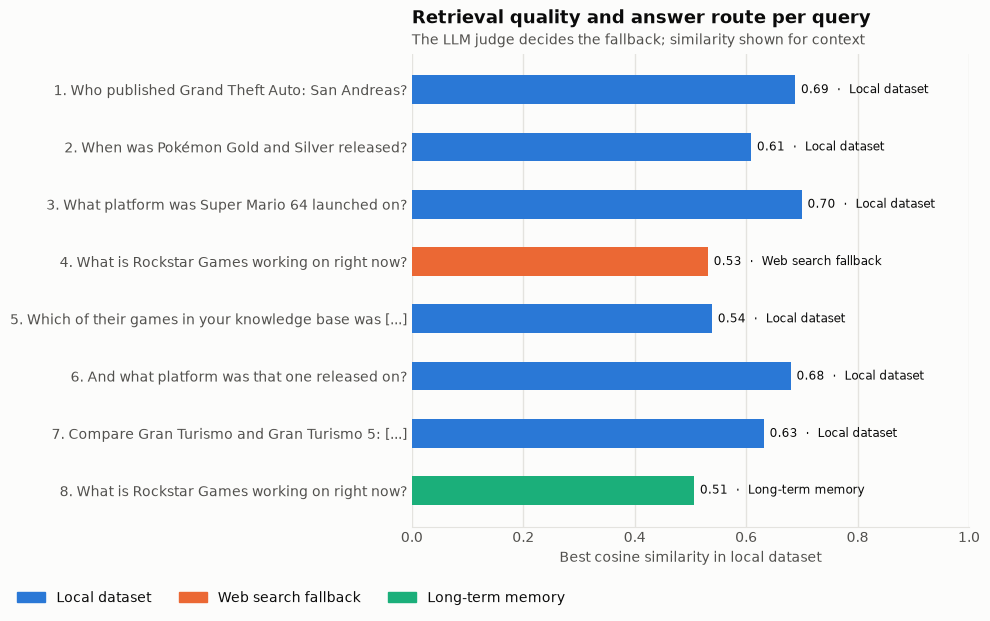

In [20]:
plot_retrieval(results);

In [21]:
print(f"{'#':<3}{'Query':<62}{'Route':<22}{'Conf.':<8}{'Cites':<7}{'Tools':<7}Tokens")
print("-" * 115)
for i, r in enumerate(results, 1):
    print(f"{i:<3}{r.query[:60]:<62}{route_of(r):<22}{r.answer.confidence:<8}"
          f"{len(r.answer.citations):<7}{len(r.tool_calls):<7}{r.total_tokens}")

#  Query                                                         Route                 Conf.   Cites  Tools  Tokens
-------------------------------------------------------------------------------------------------------------------
1  Who published Grand Theft Auto: San Andreas?                  Local dataset         high    1      2      4416
2  When was Pokémon Gold and Silver released?                    Local dataset         high    1      2      4991
3  What platform was Super Mario 64 launched on?                 Local dataset         high    1      2      6116
4  What is Rockstar Games working on right now?                  Web search fallback   high    2      3      11148
5  Which of their games in your knowledge base was released mos  Local dataset         high    1      2      8611
6  And what platform was that one released on?                   Local dataset         high    1      2      6669
7  Compare Gran Turismo and Gran Turismo 5: platforms, release   Local dataset     

## 7. Report

**What the agent does**
- Every turn starts with internal retrieval (`retrieve_game`) followed by an explicit quality check
  (`evaluate_retrieval`), both forced via `tool_choice`. Only when the evaluator says the documents are insufficient (or it has
  low confidence) does the agent call `game_web_search`. The tool executor enforces this order.
- Questions about the dataset's games (publisher, release year, platform) are answered from the local dataset
  and cite `games/<id>.json`.
- Time-sensitive questions ("right now") are recognized as not answerable from the static dataset and fall
  back to the web; those answers cite URLs.
- Follow-up questions are resolved using short-term (session) memory.
- Web findings are written to long-term memory, so a fresh session can answer the same question from memory.
- Every answer is returned as natural language **and** as validated JSON (`AgentAnswer`): answer, confidence,
  answered_from, reasoning, citations, and per-game structured facts.

**Limitations**
- The evaluator is itself an LLM, so its usefulness verdicts can occasionally be wrong; similarity scores are
  shown alongside for transparency.
- Facts in long-term memory can go stale; each one stores its `learned_at` timestamp and source URLs so the
  judge (and the user) can take its age into account.
- Retrieval returns the top 3 matches, so questions that need an exhaustive scan of the dataset
  (e.g. "compare *all* the Gran Turismo games in your knowledge base") can't be verified as complete by the
  evaluator, which may then fall back to the web. Metadata filters (Part 1) are the better tool for those.
- Web answers depend on which pages the search returns, so results for current-events questions vary between runs.
- Release years in the dataset are the first release (e.g. Pokémon Gold and Silver: 1999 in Japan).